# 03 ファンのPQ特性

固定風量からPQファンへ置き換え、開口抵抗との交点で運転点を求める。

## 到達目標
p_max、p1、q1、q_maxを一組で設定する。qの単位はm³/s。

## 実行環境
Python 3.10以上とvtsimnx engineが必要です。Colabのlocalhostは手元PCのサーバーを指しません。次の設定セルのAPI URLを到達可能なものに変更します。APIキーは環境変数で渡し、ノートに保存しません。

検証engine commit: `5eeffb2f8012a2fe41bca705450b0dd0a952326d`。入力モデルは実計算確認済ですが、原住宅の年間再現とは範囲が異なります。

## 実行版の使い方
このノートは検証対象のvtsimnx commit 5eeffb2f8012a2fe41bca705450b0dd0a952326d に合わせた代表教材です。上から順に実行します。
Pythonクライアントの導入だけではengineは起動しません。教材17以外は接続可能なengineと、必要に応じてVTSIMNX_API_KEYが必要です。Colabの127.0.0.1は手元PCのengineを指しません。
入力はノート内に含めています。元のDriveパスや測定CSVを別途読む必要はありません。
出力は教材フォルダ内のresults/03/に保存します。詳しい準備は同じフォルダの00_実行ガイド.ipynbを参照してください。


In [1]:
import os, sys, subprocess
# 検証runnerのみ専用環境で導入済みの依存を再利用する。通常はこのセルで導入する。
if os.environ.get("VTSIMNX_TUTORIAL_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip", "setuptools>=68,<81", "wheel"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "vtsimnx @ git+https://github.com/iguchi-lab/vtsimnx@5eeffb2f8012a2fe41bca705450b0dd0a952326d",
        "matplotlib", "japanize-matplotlib"])


In [2]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from IPython.display import display
import vtsimnx as vt

# ローカルJupyterでは、ノートブックと同じフォルダを作業フォルダにする。
DATA_DIR = Path(os.environ.get("VTSIMNX_TUTORIAL_DATA", ".")).expanduser().resolve()
BASE_URL = os.environ.get("VTSIMNX_API_URL", "http://127.0.0.1:8000")
API_KEY = os.environ.get("VTSIMNX_API_KEY")
OUTPUT = DATA_DIR / "results" / "03"
OUTPUT.mkdir(parents=True, exist_ok=True)


## 入力を読む
次の辞書はvtsimnxのネイティブ形式です。風量はm³/s、熱量はW、熱容量はJ/Kです。

In [3]:
configs = {'03_fan': {'builder': {},
            'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                     'end': '2026-01-01T00:00:01',
                                     'length': 2,
                                     'timestep': 1}},
            'nodes': [{'key': 'node1', 'p': 0, 't': 20},
                      {'key': 'node2', 'calc_p': True, 't': 20},
                      {'key': 'node3', 'calc_p': True, 't': 20}],
            'ventilation_branches': [{'key': 'node1->node2',
                                      'source': 'node1',
                                      'target': 'node2',
                                      'type': 'fan',
                                      'p_max': 200,
                                      'p1': 100,
                                      'q1': 0.06,
                                      'q_max': 0.1},
                                     {'key': 'node2->node3',
                                      'source': 'node2',
                                      'target': 'node3',
                                      'type': 'simple_opening',
                                      'alpha': 0.6,
                                      'area': 0.01},
                                     {'key': 'node3->node1',
                                      'source': 'node3',
                                      'target': 'node1',
                                      'type': 'simple_opening',
                                      'alpha': 0.6,
                                      'area': 0.03}],
            'thermal_branches': []}}


## 実行と結果の取得
計算ごとの要求JSONを保存し、必要な系列をDataFrameとして取得します。

In [4]:
results = {}
for name, config in configs.items():
    results[name] = vt.run_calc(BASE_URL, config, api_key=API_KEY,
        as_result=True, raise_on_error=True, timeout=1800, request_output_path=OUTPUT / (name + "_request.json"))
    print(name, results[name].artifact_dir)


03_fan artifacts.1794699387538.output.1e5664f3882f4b829c516177caa79399


03_fan


,node1->node2,node2->node3,node3->node1
time,,,
2026-01-01 00:00:00,0.066874,0.066874,0.066874
2026-01-01 00:00:01,0.066874,0.066874,0.066874


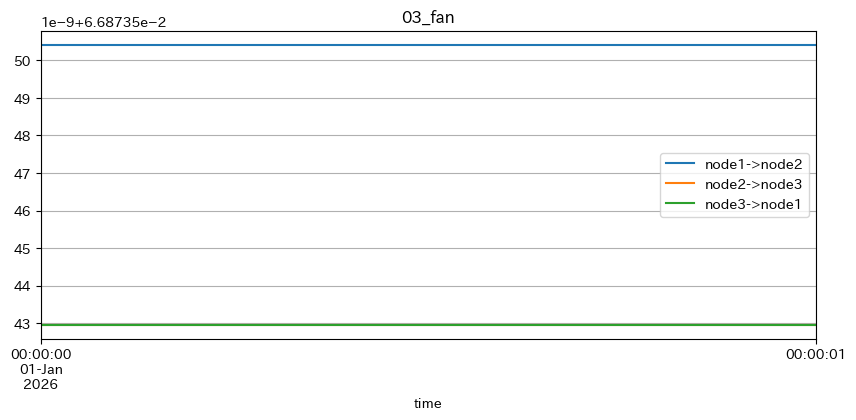

In [5]:
frames = {name: result.get_series_df('vent_flow_rate', raise_on_error=True) for name, result in results.items()}
for name, frame in frames.items():
    print(name)
    display(frame.head())
    frame.to_csv(OUTPUT / (name + "_vent_flow_rate.csv"), encoding="utf-8-sig")
    frame.plot(title=name, figsize=(10, 4), grid=True)


## 確認・発展
開口面積を小さくした際の風量減少と静圧増加を確認する。

保存された時刻の値は当該ステップ更新後の値です。初期値との比較ではこの差に注意します。

## 原典との対応
- S010 Untitled8.ipynb
- S070 240924_枚方_αA収束計算.ipynb
- S071 240925_枚方_αA収束計算.ipynb 
- S330 Untitled0.ipynb
- S369 Untitled0.ipynb
- S380 251207_vtsimnx_test.ipynb
- S381 260106_vtsim_vs_ventsim
- S400 260517_vtsim_vs_ventsim
- S405 2607012_vtsim_vs_ventsim

S番号は原典調査時の識別子です。原典の完全な台帳は管理者のDrive整理資料に保管しています。